In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, struct
import numpy as np
import kagglehub

PROJECT_DIR = "/content/drive/MyDrive/mnist_project"
os.makedirs(PROJECT_DIR, exist_ok=True)
DATA_NPZ = f"{PROJECT_DIR}/mnist.npz"

def find(root, key):
    for d, _, files in os.walk(root):
        for f in files:
            if key in f:
                return os.path.join(d, f)

def read_images(path):
    with open(path, "rb") as f:
        _, n, rows, cols = struct.unpack(">IIII", f.read(16))
        return np.frombuffer(f.read(), dtype=np.uint8).reshape(n, rows, cols)

def read_labels(path):
    with open(path, "rb") as f:
        _, n = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8)

if os.path.exists(DATA_NPZ):
    d = np.load(DATA_NPZ)
    X_train, y_train, X_test, y_test = d["X_train"], d["y_train"], d["X_test"], d["y_test"]
else:
    root = kagglehub.dataset_download("hojjatk/mnist-dataset")
    X_train = read_images(find(root, "train-images"))
    y_train = read_labels(find(root, "train-labels"))
    X_test  = read_images(find(root, "t10k-images"))
    y_test  = read_labels(find(root, "t10k-labels"))
    np.savez_compressed(DATA_NPZ, X_train=X_train, y_train=y_train, X_test=X_test, y_test=y_test)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)
print("Pixel range:", X_train.min(), "to", X_train.max(), "| dtype:", X_train.dtype)
print("Train digit counts:", np.bincount(y_train))

Mounted at /content/drive
Train: (60000, 28, 28) (60000,)
Test:  (10000, 28, 28) (10000,)
Pixel range: 0 to 255 | dtype: uint8
Train digit counts: [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


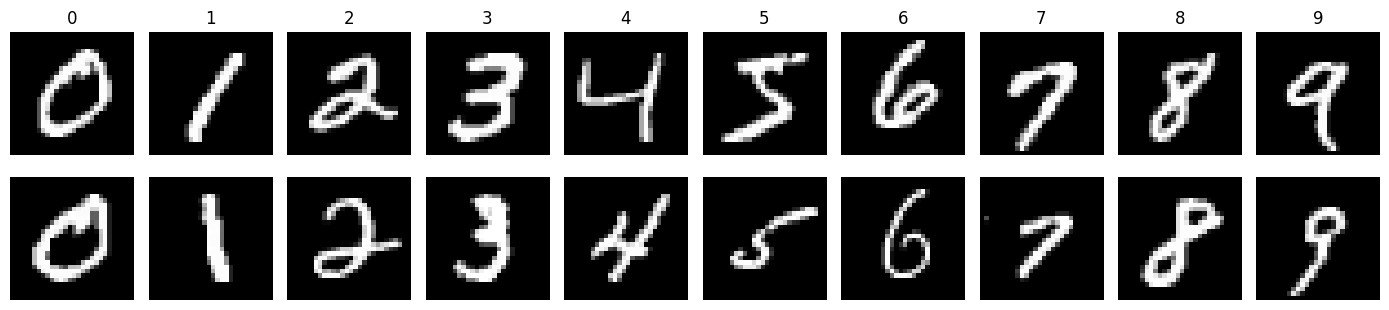

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(2, 10, figsize=(14, 3.4))
for d in range(10):
    idx = np.where(y_train == d)[0]
    for r in range(2):
        ax = axes[r, d]
        ax.imshow(X_train[idx[r]], cmap="gray")
        ax.axis("off")
        if r == 0:
            ax.set_title(str(d))
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/sample_digits.png", dpi=150)
plt.show()

In [ ]:
from tensorflow.keras.utils import to_categorical
from sklearn.model_selection import train_test_split

# 1. scale pixels from 0-255 to 0-1 and add the channel dimension the CNN expects
X_train_p = (X_train.astype("float32") / 255.0).reshape(-1, 28, 28, 1)
X_test_p  = (X_test.astype("float32") / 255.0).reshape(-1, 28, 28, 1)

# 2. one-hot encode the labels (digit 3 -> [0,0,0,1,0,0,0,0,0,0])
y_train_c = to_categorical(y_train, 10)
y_test_c  = to_categorical(y_test, 10)

# 3. hold out 10% of the training data for validation (kept balanced per digit)
X_tr, X_val, y_tr, y_val = train_test_split(
    X_train_p, y_train_c, test_size=0.1, stratify=y_train, random_state=42)

print("Train:", X_tr.shape, y_tr.shape)
print("Validation:", X_val.shape, y_val.shape)
print("Test:", X_test_p.shape, y_test_c.shape)
print("Pixel range after scaling:", X_tr.min(), "to", X_tr.max())
print("Label example:", y_train[0], "->", y_train_c[0])

Train: (54000, 28, 28, 1) (54000, 10)
Validation: (6000, 28, 28, 1) (6000, 10)
Test: (10000, 28, 28, 1) (10000, 10)
Pixel range after scaling: 0.0 to 1.0
Label example: 5 -> [0. 0. 0. 0. 0. 1. 0. 0. 0. 0.]


In [ ]:
import json
from tensorflow import keras
from tensorflow.keras import layers

MODEL_PATH = f"{PROJECT_DIR}/mnist_cnn.keras"
HIST_PATH  = f"{PROJECT_DIR}/history.json"

def build_model():
    m = keras.Sequential([
        layers.Input(shape=(28, 28, 1)),
        layers.Conv2D(32, 3, activation="relu"),
        layers.Conv2D(32, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),
        layers.Conv2D(64, 3, activation="relu"),
        layers.Conv2D(64, 3, activation="relu"),
        layers.MaxPooling2D(),
        layers.Dropout(0.25),
        layers.Flatten(),
        layers.Dense(128, activation="relu"),
        layers.Dropout(0.5),
        layers.Dense(10, activation="softmax"),
    ])
    m.compile(optimizer="adam", loss="categorical_crossentropy", metrics=["accuracy"])
    return m

if os.path.exists(MODEL_PATH) and os.path.exists(HIST_PATH):
    model = keras.models.load_model(MODEL_PATH)
    history = json.load(open(HIST_PATH))
    print("Loaded saved model, no retraining needed.")
else:
    model = build_model()
    model.summary()
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3, restore_best_weights=True),
        keras.callbacks.ModelCheckpoint(MODEL_PATH, monitor="val_accuracy", save_best_only=True),
    ]
    h = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                  epochs=20, batch_size=128, callbacks=callbacks, verbose=2)
    history = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    json.dump(history, open(HIST_PATH, "w"))
    print("Trained and saved to Drive.")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 12, 12, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 10, 10, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 4, 4, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1024)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 197,482 (771.41 KB)

 Trainable params: 197,482 (771.41 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/20
422/422 - 137s - 324ms/step - accuracy: 0.8952 - loss: 0.3267 - val_accuracy: 0.9820 - val_loss: 0.0638
Epoch 2/20
422/422 - 138s - 328ms/step - accuracy: 0.9711 - loss: 0.0965 - val_accuracy: 0.9867 - val_loss: 0.0460
Epoch 3/20
422/422 - 132s - 313ms/step - accuracy: 0.9788 - loss: 0.0710 - val_accuracy: 0.9887 - val_loss: 0.0439
Epoch 4/20
422/422 - 140s - 332ms/step - accuracy: 0.9838 - loss: 0.0565 - val_accuracy: 0.9920 - val_loss: 0.0345
Epoch 5/20
422/422 - 144s - 341ms/step - accuracy: 0.9861 - loss: 0.0476 - val_accuracy: 0.9907 - val_loss: 0.0338
Epoch 6/20
422/422 - 145s - 344ms/step - accuracy: 0.9867 - loss: 0.0433 - val_accuracy: 0.9903 - val_loss: 0.0365
Epoch 7/20
422/422 - 135s - 320ms/step - accuracy: 0.9890 - loss: 0.0374 - val_accuracy: 0.9915 - val_loss: 0.0327
Trained and saved to Drive.


Test accuracy: 0.9936 | Test loss: 0.0235

              precision    recall  f1-score   support

           0     0.9869    0.9980    0.9924       980
           1     0.9947    0.9991    0.9969      1135
           2     0.9942    0.9961    0.9952      1032
           3     0.9921    0.9970    0.9946      1010
           4     0.9949    0.9929    0.9939       982
           5     0.9966    0.9910    0.9938       892
           6     0.9968    0.9885    0.9927       958
           7     0.9932    0.9874    0.9902      1028
           8     0.9959    0.9938    0.9949       974
           9     0.9911    0.9911    0.9911      1009

    accuracy                         0.9936     10000
   macro avg     0.9936    0.9935    0.9936     10000
weighted avg     0.9936    0.9936    0.9936     10000



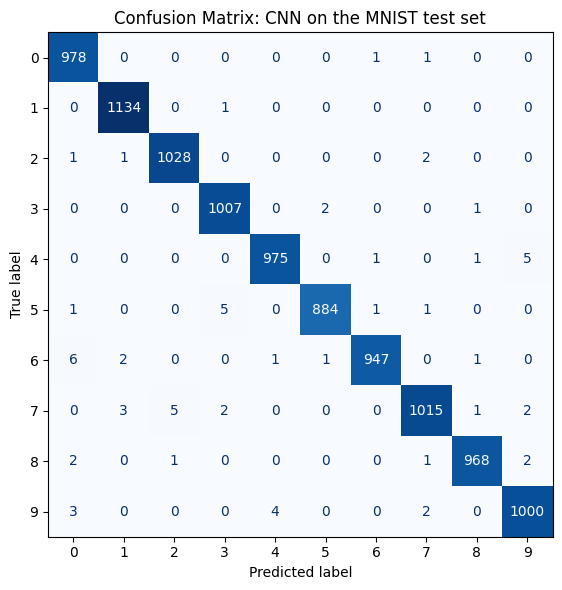

In [ ]:
from sklearn.metrics import classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

test_loss, test_acc = model.evaluate(X_test_p, y_test_c, verbose=0)
print(f"Test accuracy: {test_acc:.4f} | Test loss: {test_loss:.4f}\n")

y_pred = model.predict(X_test_p, verbose=0).argmax(axis=1)
print(classification_report(y_test, y_pred, digits=4))

fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, cmap="Blues", ax=ax, colorbar=False)
ax.set_title("Confusion Matrix: CNN on the MNIST test set")
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/confusion_matrix.png", dpi=150)
plt.show()

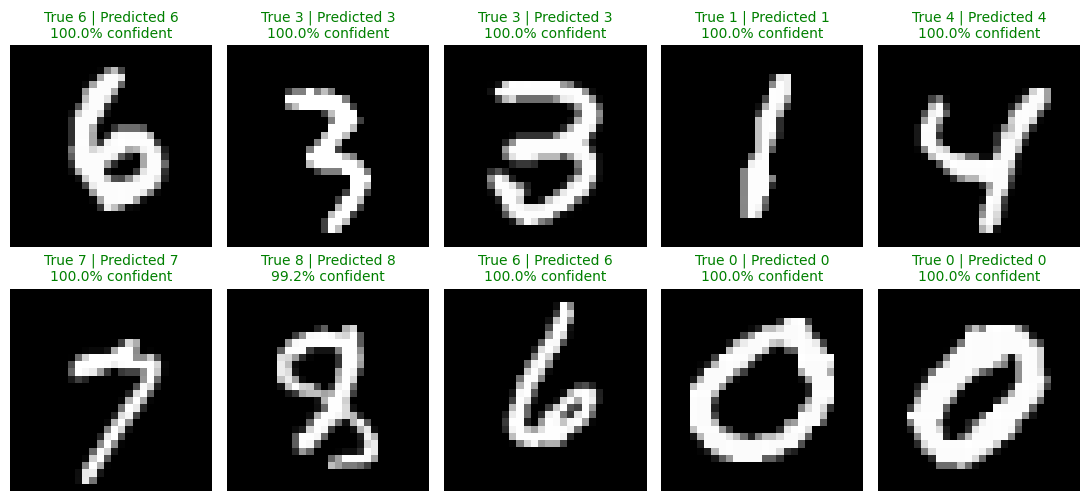

In [ ]:
import matplotlib.pyplot as plt

rng = np.random.default_rng(1)
idx = rng.choice(len(X_test_p), 10, replace=False)
probs = model.predict(X_test_p[idx], verbose=0)

fig, axes = plt.subplots(2, 5, figsize=(11, 5.2))
for ax, i, p in zip(axes.ravel(), idx, probs):
    pred = int(p.argmax())
    ax.imshow(X_test[i], cmap="gray")
    ax.axis("off")
    ax.set_title(f"True {y_test[i]} | Predicted {pred}\n{p[pred]*100:.1f}% confident",
                 color="green" if pred == y_test[i] else "red", fontsize=10)
plt.tight_layout()
plt.savefig(f"{PROJECT_DIR}/sample_predictions.png", dpi=150)
plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Saving 1.png to 1.png
1.png: predicted digit 0 (confidence 99.2%)


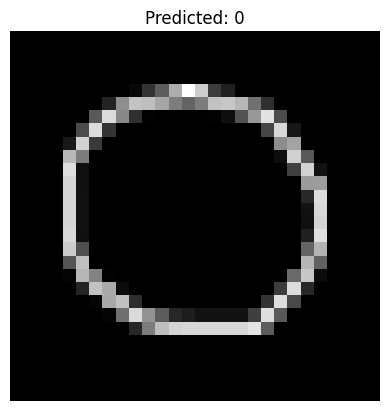

In [ ]:
from google.colab import drive, files
drive.mount('/content/drive')

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from tensorflow import keras

PROJECT_DIR = "/content/drive/MyDrive/mnist_project"
model = keras.models.load_model(f"{PROJECT_DIR}/mnist_cnn.keras")

def prepare(img):
    g = img.convert("L")
    if np.array(g).mean() > 127:           # dark ink on white paper -> invert (MNIST is white on black)
        g = ImageOps.invert(g)
    a = np.array(g)
    ys, xs = np.where(a > 50)
    if len(xs):                             # crop to the digit
        g = g.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))
    s = 20 / max(g.size)                    # scale longest side to 20 px, keep aspect ratio
    g = g.resize((max(1, round(g.width * s)), max(1, round(g.height * s))))
    canvas = Image.new("L", (28, 28), 0)    # centre on a 28x28 black canvas, like MNIST
    canvas.paste(g, ((28 - g.width) // 2, (28 - g.height) // 2))
    return np.array(canvas, dtype="float32").reshape(1, 28, 28, 1) / 255.0

uploaded = files.upload()
for name in uploaded:
    x = prepare(Image.open(name))
    probs = model.predict(x, verbose=0)[0]
    d = int(probs.argmax())
    print(f"{name}: predicted digit {d} (confidence {probs[d]*100:.1f}%)")
    plt.imshow(x[0, :, :, 0], cmap="gray")
    plt.title(f"Predicted: {d}")
    plt.axis("off")
    plt.show()

In [2]:
from google.colab import drive, output
drive.mount('/content/drive')

import io, base64
import numpy as np
from PIL import Image
from IPython.display import HTML, JSON, display
from tensorflow import keras

# ---------- load the saved model ----------
PROJECT_DIR = "/content/drive/MyDrive/mnist_project"
model = keras.models.load_model(f"{PROJECT_DIR}/mnist_cnn.keras")

# ---------- turn the drawing into a 28x28 MNIST-style image ----------
def prepare_canvas(img):
    if img.mode == "RGBA":                                   # flatten transparency onto black
        bg = Image.new("RGBA", img.size, (0, 0, 0, 255))
        img = Image.alpha_composite(bg, img)
    g = img.convert("L")
    a = np.array(g)
    ys, xs = np.where(a > 40)
    g = g.crop((xs.min(), ys.min(), xs.max() + 1, ys.max() + 1))      # crop to the digit
    s = 20 / max(g.size)                                              # longest side -> 20 px
    g = g.resize((max(1, round(g.width * s)), max(1, round(g.height * s))), Image.LANCZOS)
    arr = np.array(g, dtype="float32")
    arr = arr * (255.0 / arr.max())                                   # stretch to full white like MNIST strokes
    g = Image.fromarray(arr.astype("uint8"))
    out = Image.new("L", (28, 28), 0)                                 # centre on 28x28 black canvas
    out.paste(g, ((28 - g.width) // 2, (28 - g.height) // 2))
    return out

def predict_canvas(data_url):
    try:
        img = Image.open(io.BytesIO(base64.b64decode(data_url.split(",", 1)[1])))
        if np.array(img.convert("L")).max() < 40:                     # nothing drawn yet
            return JSON({"empty": True})
        small = prepare_canvas(img)
        x = (np.array(small, dtype="float32") / 255.0).reshape(1, 28, 28, 1)
        probs = model.predict(x, verbose=0)[0]
        buf = io.BytesIO()
        small.resize((112, 112), Image.NEAREST).save(buf, format="PNG")
        return JSON({"digit": int(probs.argmax()),
                     "probs": [float(p) for p in probs],
                     "preview": "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()})
    except Exception as e:
        return JSON({"error": str(e)})

output.register_callback("mnist.predict", predict_canvas)

# ---------- the interface ----------
UI = r"""
<style>
#dp{--bg:#0b1220;--panel:#111a2e;--line:#243049;--tx:#e5e7eb;--mut:#94a3b8;--acc:#6366f1;--ok:#22c55e;--warn:#f59e0b;
  font-family:system-ui,-apple-system,"Segoe UI",Roboto,Arial,sans-serif;color:var(--tx);background:var(--bg);
  border-radius:16px;padding:18px;max-width:800px;box-sizing:border-box}
#dp *{box-sizing:border-box}
#dp .hdr{padding:16px 20px;border-radius:12px;background:linear-gradient(135deg,#4f46e5,#7c3aed);color:#fff}
#dp .hdr h2{margin:0;font-size:22px;color:#fff}
#dp .hdr p{margin:4px 0 0;font-size:13px;opacity:.92}
#dp .row{display:flex;gap:16px;flex-wrap:wrap;margin-top:16px}
#dp .col{flex:1 1 300px;min-width:280px}
#dp .box{background:var(--panel);border:1px solid var(--line);border-radius:12px;padding:14px}
#dp .title{font-size:12px;font-weight:700;letter-spacing:.06em;text-transform:uppercase;color:var(--mut);margin:0 0 10px}
#dp .cwrap{position:relative;width:280px;height:280px;margin:0 auto;border-radius:10px;overflow:hidden;border:2px solid var(--acc)}
#dp canvas{display:block;width:280px;height:280px;background:#000;cursor:crosshair;touch-action:none}
#dp .hint{position:absolute;inset:0;display:flex;align-items:center;justify-content:center;color:#64748b;font-size:15px;pointer-events:none}
#dp .ctrl{display:flex;align-items:center;gap:10px;margin-top:12px;flex-wrap:wrap}
#dp .ctrl label{font-size:13px;color:var(--mut)}
#dp .ctrl input[type=range]{flex:1;min-width:90px;accent-color:var(--acc)}
#dp button{border:0;border-radius:8px;padding:9px 16px;font-size:14px;font-weight:600;cursor:pointer;background:#334155;color:#fff}
#dp button:hover{background:#475569}
#dp .top{display:flex;align-items:center;gap:14px;flex-wrap:wrap}
#dp .big{width:92px;height:92px;border-radius:14px;display:flex;align-items:center;justify-content:center;font-size:60px;font-weight:800;
  background:#0b1220;border:2px solid var(--line);color:var(--mut)}
#dp .meta{flex:1;min-width:110px}
#dp .lbl{font-size:12px;color:var(--mut);text-transform:uppercase;letter-spacing:.06em}
#dp .conf{font-size:22px;font-weight:700;margin-top:2px}
#dp .mut{color:var(--mut);font-size:13px}
#dp .pv{text-align:center}
#dp .pv img{width:84px;height:84px;image-rendering:pixelated;border:1px solid var(--line);border-radius:8px;background:#000;display:block}
#dp .pv .cap{font-size:11px;color:var(--mut);margin-top:4px}
#dp .brow{display:flex;align-items:center;gap:8px;margin:5px 0;font-size:13px}
#dp .brow .d{width:14px;text-align:right;font-weight:700}
#dp .track{flex:1;height:12px;background:#0b1220;border-radius:8px;overflow:hidden}
#dp .fill{height:100%;width:0;background:#475569;border-radius:8px;transition:width .25s}
#dp .brow.top1 .fill{background:var(--acc)}
#dp .brow .p{width:52px;text-align:right;color:var(--mut)}
#dp .hist{display:flex;gap:6px;flex-wrap:wrap}
#dp .chip{padding:4px 10px;border-radius:999px;font-size:13px;font-weight:600;background:#0b1220;border:1px solid var(--line)}
#dp .err{color:#f87171;font-size:13px;margin-top:8px}
</style>

<div id="dp">
  <div class="hdr">
    <h2>Digit Recognizer</h2>
    <p>CNN trained on MNIST &middot; 197,482 parameters &middot; 99.36% test accuracy &middot; draw a digit from 0 to 9</p>
  </div>
  <div class="row">
    <div class="col box">
      <p class="title">Draw here</p>
      <div class="cwrap">
        <canvas id="dp-cv" width="280" height="280"></canvas>
        <div class="hint" id="dp-hint">Draw a digit with the mouse</div>
      </div>
      <div class="ctrl">
        <label for="dp-size">Brush</label>
        <input type="range" id="dp-size" min="12" max="34" value="22">
        <button id="dp-clear" title="Clears the pad and saves the last prediction to the history">Clear</button>
      </div>
    </div>
    <div class="col box">
      <p class="title">Prediction</p>
      <div class="top">
        <div class="big" id="dp-digit">?</div>
        <div class="meta">
          <div class="lbl">Confidence</div>
          <div class="conf" id="dp-conf">&ndash;</div>
          <div class="mut" id="dp-status">Waiting for a drawing</div>
        </div>
        <div class="pv"><img id="dp-prev" alt="model input"><div class="cap">What the model sees</div></div>
      </div>
      <p class="title" style="margin-top:16px">Probability of each digit</p>
      <div id="dp-bars"></div>
      <p class="title" style="margin-top:14px">History</p>
      <div class="hist" id="dp-hist"><span class="mut">Press Clear to save a drawing here.</span></div>
      <div class="err" id="dp-err"></div>
    </div>
  </div>
</div>

<script>
(function(){
  const $ = (id) => document.getElementById(id);
  const cv = $('dp-cv'), ctx = cv.getContext('2d');
  const bars = $('dp-bars');
  for (let d = 0; d < 10; d++) {
    const r = document.createElement('div');
    r.className = 'brow'; r.id = 'dp-b' + d;
    r.innerHTML = '<span class="d">' + d + '</span><div class="track"><div class="fill"></div></div><span class="p">0.0%</span>';
    bars.appendChild(r);
  }
  let drawing = false, last = null, hasInk = false, busy = false, pending = false, lastCall = 0;
  let current = null, history = [];

  function blank() { ctx.fillStyle = '#000'; ctx.fillRect(0, 0, 280, 280); }
  blank();

  function pos(e) {
    const r = cv.getBoundingClientRect();
    return [(e.clientX - r.left) * 280 / r.width, (e.clientY - r.top) * 280 / r.height];
  }
  function stroke(a, b) {
    ctx.strokeStyle = '#fff'; ctx.lineWidth = +$('dp-size').value;
    ctx.lineCap = 'round'; ctx.lineJoin = 'round';
    ctx.beginPath(); ctx.moveTo(a[0], a[1]); ctx.lineTo(b[0], b[1]); ctx.stroke();
  }
  cv.addEventListener('pointerdown', (e) => {
    e.preventDefault(); cv.setPointerCapture(e.pointerId);
    drawing = true; hasInk = true; $('dp-hint').style.display = 'none';
    last = pos(e); stroke(last, last);
  });
  cv.addEventListener('pointermove', (e) => {
    if (!drawing) return;
    const p = pos(e); stroke(last, p); last = p;
    const now = Date.now();
    if (now - lastCall > 350) { lastCall = now; predict(); }      // live update while drawing
  });
  const end = () => { if (!drawing) return; drawing = false; setTimeout(predict, 60); };
  cv.addEventListener('pointerup', end);
  cv.addEventListener('pointercancel', end);

  function setBars(probs) {
    const top = probs.indexOf(Math.max.apply(null, probs));
    for (let d = 0; d < 10; d++) {
      const row = $('dp-b' + d);
      row.classList.toggle('top1', d === top);
      row.querySelector('.fill').style.width = (probs[d] * 100).toFixed(1) + '%';
      row.querySelector('.p').textContent = (probs[d] * 100).toFixed(1) + '%';
    }
  }
  function show(r) {
    $('dp-err').textContent = '';
    if (r.error) { $('dp-err').textContent = 'Error: ' + r.error; return; }
    if (r.empty) { resetView(); return; }
    const conf = r.probs[r.digit];
    current = { digit: r.digit, conf: conf };
    const big = $('dp-digit');
    big.textContent = r.digit; big.style.color = '#fff'; big.style.borderColor = conf >= 0.9 ? '#22c55e' : '#f59e0b';
    $('dp-conf').textContent = (conf * 100).toFixed(1) + '%';
    $('dp-conf').style.color = conf >= 0.9 ? '#22c55e' : '#f59e0b';
    $('dp-status').textContent = conf >= 0.9 ? 'High confidence' : 'Low confidence, try drawing it clearer';
    $('dp-prev').src = r.preview;
    setBars(r.probs);
  }
  function resetView() {
    current = null;
    const big = $('dp-digit'); big.textContent = '?'; big.style.color = ''; big.style.borderColor = '';
    $('dp-conf').textContent = '\u2013'; $('dp-conf').style.color = '';
    $('dp-status').textContent = 'Waiting for a drawing';
    $('dp-prev').removeAttribute('src');
    setBars(new Array(10).fill(0));
  }
  function renderHistory() {
    const h = $('dp-hist'); h.innerHTML = '';
    if (!history.length) { h.innerHTML = '<span class="mut">Press Clear to save a drawing here.</span>'; return; }
    history.forEach((x) => {
      const c = document.createElement('span'); c.className = 'chip';
      c.textContent = x.digit + '  (' + (x.conf * 100).toFixed(0) + '%)';
      h.appendChild(c);
    });
  }

  async function predict() {
    if (!hasInk) return;
    if (typeof google === 'undefined' || !google.colab) {
      $('dp-err').textContent = 'This interface needs to run inside Google Colab.'; return;
    }
    if (busy) { pending = true; return; }
    busy = true;
    try {
      const res = await google.colab.kernel.invokeFunction('mnist.predict', [cv.toDataURL('image/png')], {});
      show(res.data['application/json']);
    } catch (err) {
      $('dp-err').textContent = 'Could not reach the Python model. Keep the cell running and try again. (' + err + ')';
    }
    busy = false;
    if (pending) { pending = false; predict(); }
  }

  $('dp-clear').addEventListener('click', () => {
    if (current) { history.unshift(current); history = history.slice(0, 10); renderHistory(); }
    blank(); hasInk = false; $('dp-hint').style.display = ''; resetView();
  });
  resetView(); renderHistory();
})();
</script>
"""

display(HTML(UI))

Mounted at /content/drive
